# Aurora precipitation-type verification against mPING

This notebook performs the complete **Aurora-only** verification workflow for:

- EDNN/ML precipitation type (`ML_ptype`)
- Bourgouin precipitation type (`BOURG_ptype`)
- mPING observations

Verification period: **1 December 2021–31 March 2022**.

Important design choices:

1. Only mPING valid times at **00, 06, 12, and 18 UTC** are used.
2. The +0 h initialization state is never verified.
3. Forecast Day 1 = +6, +12, +18, +24 h; Day 2 = +30, +36, +42, +48 h; ...; Day 7 = +150, +156, +162, +168 h.
4. mPING is restricted to the common forecast domain **24–50°N, 125–66°W before nearest-neighbor collocation**.
5. Forecast fields are matched to the nearest Aurora grid point. Match distance is retained for QC.
6. `ML_ptype == -1` is treated as an invalid ML diagnosis.
7. **ML and Bourgouin skill are compared on the same common-valid sample** so differences cannot arise from unequal samples.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

# ============================================================
# PATHS / CONFIG
# ============================================================

MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"
BASE_DIR = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
AURORA_DIR = BASE_DIR / "au_ptype"

OUT_DIR = BASE_DIR / "verification"
OUT_DIR.mkdir(parents=True, exist_ok=True)

START_VALID = pd.Timestamp("2021-12-01 00:00:00")
END_VALID   = pd.Timestamp("2022-04-01 00:00:00")  # exclusive

CONSENSUS_THRESHOLD = 70.0
LAT_MIN, LAT_MAX = 24.0, 50.0
LON_MIN, LON_MAX = -125.0, -66.0
MAX_MATCH_DISTANCE_KM = 30.0

PTYPE_COLS = {
    "sn_percent": "Snow",
    "ra_percent": "Rain",
    "pl_percent": "Ice Pellet",
    "fzra_percent": "Freezing Rain",
}

# Forecast class encoding from the saved ptype files
CLASS_NAMES = {
    0: "Rain",
    1: "Snow",
    2: "Ice Pellet",
    3: "Freezing Rain",
}
CLASS_CODES = {v: k for k, v in CLASS_NAMES.items()}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]

FORECAST_VARS = [
    "ML_ptype",
    "ML_rain", "ML_snow", "ML_icep", "ML_frzr",
    "ML_u",
    "ML_rain_ale", "ML_snow_ale", "ML_icep_ale", "ML_frzr_ale",
    "ML_rain_epi", "ML_snow_epi", "ML_icep_epi", "ML_frzr_epi",
    "BOURG_ptype",
]


## 1. Prepare mPING observations


In [2]:
def prepare_mping(path, consensus_threshold=70.0):
    cols = [
        "datetime", "lat", "lon", "report_count",
        "sn_percent", "ra_percent", "pl_percent", "fzra_percent",
    ]

    df = pd.read_parquet(path, columns=cols)
    df["datetime"] = pd.to_datetime(df["datetime"])

    # Verification period
    df = df[(df["datetime"] >= START_VALID) & (df["datetime"] < END_VALID)].copy()

    # Exact forecast-valid synoptic times
    df = df[df["datetime"].dt.hour.isin([0, 6, 12, 18])].copy()

    # Restrict observations to the forecast CONUS domain BEFORE nearest-neighbor matching
    df = df[
        df["lat"].between(LAT_MIN, LAT_MAX) &
        df["lon"].between(LON_MIN, LON_MAX)
    ].copy()

    pcols = list(PTYPE_COLS)
    df["obs_class"] = df[pcols].idxmax(axis=1).map(PTYPE_COLS)
    df["obs_consensus"] = df[pcols].max(axis=1)

    if df["obs_consensus"].max() <= 1:
        df["obs_consensus"] *= 100

    df = df[df["obs_consensus"] >= consensus_threshold].copy()
    df = df.reset_index(drop=True)
    df["obs_id"] = np.arange(len(df), dtype=np.int64)

    return df[
        ["obs_id", "datetime", "lat", "lon",
         "report_count", "obs_class", "obs_consensus"]
    ]


mping_obs = prepare_mping(MPING_PATH, CONSENSUS_THRESHOLD)

print(f"Retained mPING observations: {len(mping_obs):,}")
print(f"Period: {mping_obs.datetime.min()} to {mping_obs.datetime.max()}")
print("\nCounts by UTC hour:")
print(mping_obs["datetime"].dt.hour.value_counts().sort_index())
print("\nCounts by precipitation type:")
print(mping_obs["obs_class"].value_counts().reindex(CLASS_ORDER))


Retained mPING observations: 29,834
Period: 2021-12-01 00:00:00 to 2022-03-31 18:00:00

Counts by UTC hour:
datetime
0      7682
6      5486
12     5440
18    11226
Name: count, dtype: int64

Counts by precipitation type:
obs_class
Rain             11902
Snow             15894
Ice Pellet        1220
Freezing Rain      818
Name: count, dtype: int64


## 2. Expand each mPING valid time to Forecast Days 1–7


In [3]:
def expand_forecast_days(obs):
    frames = []

    for forecast_day in range(1, 8):
        x = obs.copy()
        hour = x["datetime"].dt.hour

        x["forecast_day"] = forecast_day
        x["lead_hour"] = np.where(
            hour == 0,
            24 * forecast_day,
            hour + 24 * (forecast_day - 1),
        ).astype(np.int16)

        x["init_time"] = x["datetime"] - pd.to_timedelta(x["lead_hour"], unit="h")
        frames.append(x)

    return pd.concat(frames, ignore_index=True)


matches = expand_forecast_days(mping_obs)

assert matches.groupby("obs_id").size().eq(7).all()
assert matches["lead_hour"].between(6, 168).all()
assert not (matches["lead_hour"] == 0).any()

print(f"mPING observations: {len(mping_obs):,}")
print(f"Expanded matchup rows: {len(matches):,}")
print("\nLead hours by forecast day:")
print(matches.groupby("forecast_day")["lead_hour"].apply(lambda x: sorted(x.unique())))


mPING observations: 29,834
Expanded matchup rows: 208,838

Lead hours by forecast day:
forecast_day
1         [6, 12, 18, 24]
2        [30, 36, 42, 48]
3        [54, 60, 66, 72]
4        [78, 84, 90, 96]
5    [102, 108, 114, 120]
6    [126, 132, 138, 144]
7    [150, 156, 162, 168]
Name: lead_hour, dtype: object


In [5]:
def show_time_mapping(matches, valid_time):
    return (
        matches[matches["datetime"] == pd.Timestamp(valid_time)]
        [["forecast_day", "init_time", "lead_hour"]]
        .drop_duplicates()
        .sort_values("forecast_day")
        .reset_index(drop=True)
    )

display(show_time_mapping(matches, "2022-02-03 00:00:00"))
display(show_time_mapping(matches, "2022-02-03 12:00:00"))


,forecast_day,init_time,lead_hour
0,1,2022-02-02,24
1,2,2022-02-01,48
2,3,2022-01-31,72
3,4,2022-01-30,96
4,5,2022-01-29,120
5,6,2022-01-28,144
6,7,2022-01-27,168


,forecast_day,init_time,lead_hour
0,1,2022-02-03,12
1,2,2022-02-02,36
2,3,2022-02-01,60
3,4,2022-01-31,84
4,5,2022-01-30,108
5,6,2022-01-29,132
6,7,2022-01-28,156


## 3. Collocate Aurora forecasts to mPING


In [6]:
class AuroraMPINGCollocator:

    def __init__(self, aurora_dir, max_distance_km=30.0):
        self.aurora_dir = Path(aurora_dir)
        self.max_distance_km = max_distance_km

    def forecast_path(self, init_time, lead_hour):
        init_str = pd.Timestamp(init_time).strftime("%Y-%m-%dT00Z")
        return self.aurora_dir / init_str / f"aurora_{init_str}_{int(lead_hour):03d}.nc"

    @staticmethod
    def haversine(lat1, lon1, lat2, lon2):
        R = 6371.0
        lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
        dlat, dlon = lat2 - lat1, lon2 - lon1
        a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
        return 2 * R * np.arcsin(np.sqrt(a))

    def extract_group(self, ds, group):
        lat_da = xr.DataArray(group["lat"].to_numpy(), dims="obs")
        lon_da = xr.DataArray(group["lon"].to_numpy(), dims="obs")

        selected = ds.sel(latitude=lat_da, longitude=lon_da, method="nearest")
        result = group.copy().reset_index(drop=True)

        result["grid_lat"] = np.asarray(selected["latitude"])
        result["grid_lon"] = np.asarray(selected["longitude"])
        result["grid_distance_km"] = self.haversine(
            result["lat"].to_numpy(), result["lon"].to_numpy(),
            result["grid_lat"].to_numpy(), result["grid_lon"].to_numpy(),
        )
        result["spatial_match_valid"] = result["grid_distance_km"] <= self.max_distance_km

        for var in FORECAST_VARS:
            if var in selected:
                result[var] = np.asarray(selected[var]).squeeze()

        return result

    def run(self, matches):
        output = []
        grouped = matches.groupby(["init_time", "lead_hour"], sort=True)
        n = len(grouped)

        for i, ((init_time, lead_hour), group) in enumerate(grouped, 1):
            path = self.forecast_path(init_time, lead_hour)

            if not path.exists():
                print(f"[MISSING] {path}")
                continue

            if i == 1 or i % 100 == 0 or i == n:
                print(f"Aurora: {i}/{n} | {init_time} +{lead_hour:03d} h | Nobs={len(group)}")

            # decode_timedelta=False removes the xarray FutureWarning; these variables
            # are not needed for the ptype extraction.
            with xr.open_dataset(path, decode_timedelta=False) as ds:
                output.append(self.extract_group(ds, group))

        if not output:
            raise RuntimeError("No Aurora forecast files were collocated.")

        return pd.concat(output, ignore_index=True)


collocator = AuroraMPINGCollocator(AURORA_DIR, MAX_MATCH_DISTANCE_KM)
aurora = collocator.run(matches)

print(f"\nCollocated rows: {len(aurora):,}")


Aurora: 1/3325 | 2021-11-24 00:00:00 +168 h | Nobs=8


/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


Aurora: 100/3325 | 2021-12-01 00:00:00 +072 h | Nobs=2
Aurora: 200/3325 | 2021-12-05 00:00:00 +024 h | Nobs=62
Aurora: 300/3325 | 2021-12-08 00:00:00 +120 h | Nobs=18
Aurora: 400/3325 | 2021-12-12 00:00:00 +048 h | Nobs=24
Aurora: 500/3325 | 2021-12-15 00:00:00 +144 h | Nobs=6
Aurora: 600/3325 | 2021-12-19 00:00:00 +072 h | Nobs=34
Aurora: 700/3325 | 2021-12-22 00:00:00 +168 h | Nobs=102
Aurora: 800/3325 | 2021-12-26 00:00:00 +096 h | Nobs=72
Aurora: 900/3325 | 2021-12-30 00:00:00 +024 h | Nobs=106
Aurora: 1000/3325 | 2022-01-02 00:00:00 +120 h | Nobs=102
Aurora: 1100/3325 | 2022-01-06 00:00:00 +048 h | Nobs=24
Aurora: 1200/3325 | 2022-01-09 00:00:00 +168 h | Nobs=74
Aurora: 1300/3325 | 2022-01-13 00:00:00 +114 h | Nobs=122
Aurora: 1400/3325 | 2022-01-17 00:00:00 +042 h | Nobs=46
Aurora: 1500/3325 | 2022-01-20 00:00:00 +138 h | Nobs=44
Aurora: 1600/3325 | 2022-01-24 00:00:00 +066 h | Nobs=22
Aurora: 1700/3325 | 2022-01-28 00:00:00 +030 h | Nobs=186
Aurora: 1800/3325 | 2022-02-01 00:00:

## 4. Collocation QC


In [7]:
print("Unique observations by forecast day:")
print(aurora.groupby("forecast_day")["obs_id"].nunique())

print("\nGrid-distance QC:")
print(aurora["grid_distance_km"].describe(percentiles=[.50, .90, .95, .99]))

print("\nSpatial matches >30 km:")
print((~aurora["spatial_match_valid"]).sum())

print("\nMissing/invalid forecast fields:")
print(aurora[["ML_ptype", "BOURG_ptype", "ML_u"]].isna().sum())
print("ML_ptype == -1:", (aurora["ML_ptype"] == -1).sum())

print("\nForecast class counts:")
print("ML:")
print(aurora["ML_ptype"].value_counts(dropna=False).sort_index())
print("\nBourgouin:")
print(aurora["BOURG_ptype"].value_counts(dropna=False).sort_index())


Unique observations by forecast day:
forecast_day
1    29834
2    29834
3    29834
4    29834
5    29834
6    29834
7    29834
Name: obs_id, dtype: int64

Grid-distance QC:
count    208838.000000
mean          9.480726
std           3.657784
min           0.329146
50%           9.736089
90%          14.096847
95%          15.010734
99%          16.345913
max          18.233566
Name: grid_distance_km, dtype: float64

Spatial matches >30 km:
0

Missing/invalid forecast fields:
ML_ptype         0
BOURG_ptype      0
ML_u           148
dtype: int64
ML_ptype == -1: 148

Forecast class counts:
ML:
ML_ptype
-1       148
 0     87024
 1    112478
 2      4038
 3      5150
Name: count, dtype: int64

Bourgouin:
BOURG_ptype
0    96150
1    98388
2     4374
3     9926
Name: count, dtype: int64


In [8]:
# Save the full collocation table BEFORE verification filtering.
COLLOCATION_FILE = OUT_DIR / "aurora_mping_collocations.parquet"
aurora.to_parquet(COLLOCATION_FILE, index=False)
print(f"Saved: {COLLOCATION_FILE}")


Saved: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/verification/aurora_mping_collocations.parquet


## 5. Build the common verification sample

For the primary ML-vs-Bourgouin comparison, both methods are evaluated on exactly the same rows:

- valid spatial match,
- valid mPING class,
- ML class in 0–3,
- Bourgouin class in 0–3.

This intentionally removes `ML_ptype == -1` from **both** methods for the direct comparison.


In [9]:
verify = aurora[
    aurora["spatial_match_valid"] &
    aurora["obs_class"].isin(CLASS_ORDER) &
    aurora["ML_ptype"].isin(CLASS_NAMES) &
    aurora["BOURG_ptype"].isin(CLASS_NAMES)
].copy()

verify["obs_code"] = verify["obs_class"].map(CLASS_CODES).astype(int)
verify["ML_ptype"] = verify["ML_ptype"].astype(int)
verify["BOURG_ptype"] = verify["BOURG_ptype"].astype(int)

print(f"Full collocation rows: {len(aurora):,}")
print(f"Common verification rows: {len(verify):,}")
print(f"Removed from common comparison: {len(aurora) - len(verify):,}")

print("\nCommon sample by forecast day:")
print(verify.groupby("forecast_day").size())

print("\nObserved classes in common sample:")
print(verify["obs_class"].value_counts().reindex(CLASS_ORDER))


Full collocation rows: 208,838
Common verification rows: 208,690
Removed from common comparison: 148

Common sample by forecast day:
forecast_day
1    29814
2    29806
3    29814
4    29792
5    29814
6    29828
7    29822
dtype: int64

Observed classes in common sample:
obs_class
Rain              83282
Snow             111144
Ice Pellet         8538
Freezing Rain      5726
Name: count, dtype: int64


## 6. Categorical verification metrics

Each precipitation type is evaluated one-vs-rest.

- **POD** = TP / (TP + FN)
- **FAR** = FP / (TP + FP)
- **CSI** = TP / (TP + FN + FP)
- **Precision** = TP / (TP + FP) = 1 − FAR
- **F1** = 2TP / (2TP + FP + FN)

Accuracy is also reported, but CSI/POD/FAR/F1 are more useful for the rarer mixed-phase classes.


In [10]:
def safe_div(num, den):
    return np.nan if den == 0 else num / den


def binary_class_metrics(obs, pred, class_code):
    obs_yes = np.asarray(obs) == class_code
    pred_yes = np.asarray(pred) == class_code

    tp = np.sum(obs_yes & pred_yes)
    fn = np.sum(obs_yes & ~pred_yes)
    fp = np.sum(~obs_yes & pred_yes)
    tn = np.sum(~obs_yes & ~pred_yes)

    return {
        "N": len(obs),
        "Observed": int(tp + fn),
        "Forecast": int(tp + fp),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "POD": safe_div(tp, tp + fn),
        "FAR": safe_div(fp, tp + fp),
        "CSI": safe_div(tp, tp + fn + fp),
        "Precision": safe_div(tp, tp + fp),
        "F1": safe_div(2 * tp, 2 * tp + fp + fn),
        "Accuracy": safe_div(tp + tn, tp + tn + fp + fn),
    }


def verification_table(df, pred_col, method, forecast_day=None):
    rows = []
    data = df if forecast_day is None else df[df["forecast_day"] == forecast_day]

    for code_, name in CLASS_NAMES.items():
        row = binary_class_metrics(data["obs_code"], data[pred_col], code_)
        row.update({
            "Method": method,
            "Forecast_Day": "All" if forecast_day is None else forecast_day,
            "Class": name,
        })
        rows.append(row)

    return pd.DataFrame(rows)


# Overall skill
overall_ml = verification_table(verify, "ML_ptype", "ML")
overall_bg = verification_table(verify, "BOURG_ptype", "Bourgouin")
overall_skill = pd.concat([overall_ml, overall_bg], ignore_index=True)

display(
    overall_skill[
        ["Method", "Class", "Observed", "Forecast", "POD", "FAR", "CSI", "F1", "Accuracy"]
    ].round(3)
)


,Method,Class,Observed,Forecast,POD,FAR,CSI,F1,Accuracy
0,ML,Rain,83282,87024,0.876,0.162,0.749,0.857,0.883
1,ML,Snow,111144,112478,0.887,0.123,0.789,0.882,0.873
2,ML,Ice Pellet,8538,4038,0.238,0.498,0.192,0.323,0.959
3,ML,Freezing Rain,5726,5150,0.320,0.644,0.203,0.337,0.965
4,Bourgouin,Rain,83282,96112,0.893,0.226,0.708,0.829,0.853
5,Bourgouin,Snow,111144,98280,0.801,0.094,0.740,0.850,0.850
6,Bourgouin,Ice Pellet,8538,4374,0.251,0.509,0.199,0.332,0.959
7,Bourgouin,Freezing Rain,5726,9924,0.399,0.770,0.171,0.292,0.947


In [11]:
# Skill by forecast day
daily_skill = []

for day in range(1, 8):
    daily_skill.append(verification_table(verify, "ML_ptype", "ML", day))
    daily_skill.append(verification_table(verify, "BOURG_ptype", "Bourgouin", day))

daily_skill = pd.concat(daily_skill, ignore_index=True)

SKILL_FILE = OUT_DIR / "aurora_mping_ptype_skill_by_forecast_day.csv"
daily_skill.to_csv(SKILL_FILE, index=False)

display(
    daily_skill[
        ["Forecast_Day", "Method", "Class", "Observed", "Forecast", "POD", "FAR", "CSI", "F1"]
    ].round(3).head(24)
)

print(f"Saved: {SKILL_FILE}")


,Forecast_Day,Method,Class,Observed,Forecast,POD,FAR,CSI,F1
0,1,ML,Rain,11900,11514,0.910,0.059,0.861,0.925
1,1,ML,Snow,15876,16686,0.965,0.082,0.889,0.941
2,1,ML,Ice Pellet,1220,742,0.392,0.356,0.322,0.487
3,1,ML,Freezing Rain,818,872,0.440,0.587,0.271,0.426
4,1,Bourgouin,Rain,11900,12414,0.912,0.126,0.806,0.893
5,1,Bourgouin,Snow,15876,15018,0.897,0.052,0.854,0.921
6,1,Bourgouin,Ice Pellet,1220,736,0.366,0.394,0.295,0.456
7,1,Bourgouin,Freezing Rain,818,1646,0.553,0.725,0.225,0.367
8,2,ML,Rain,11898,11824,0.907,0.088,0.834,0.909
9,2,ML,Snow,15870,16446,0.945,0.088,0.866,0.928


Saved: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/verification/aurora_mping_ptype_skill_by_forecast_day.csv


## 7. Overall ML vs Bourgouin skill plots


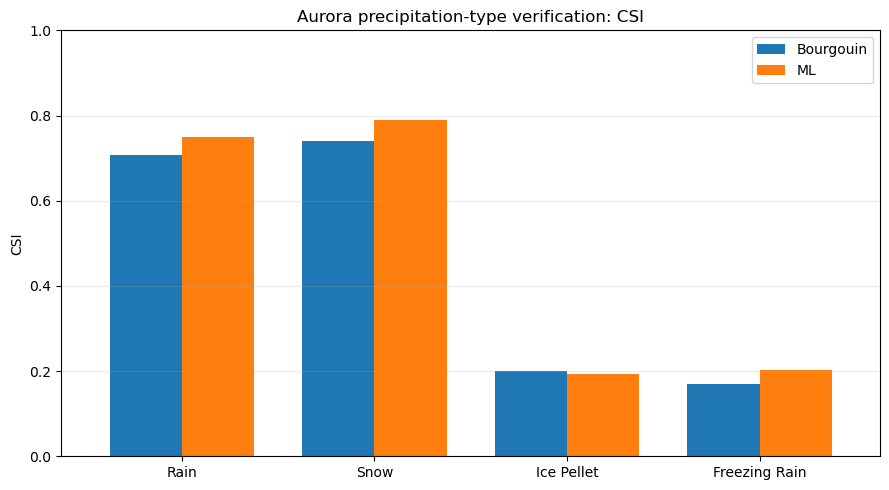

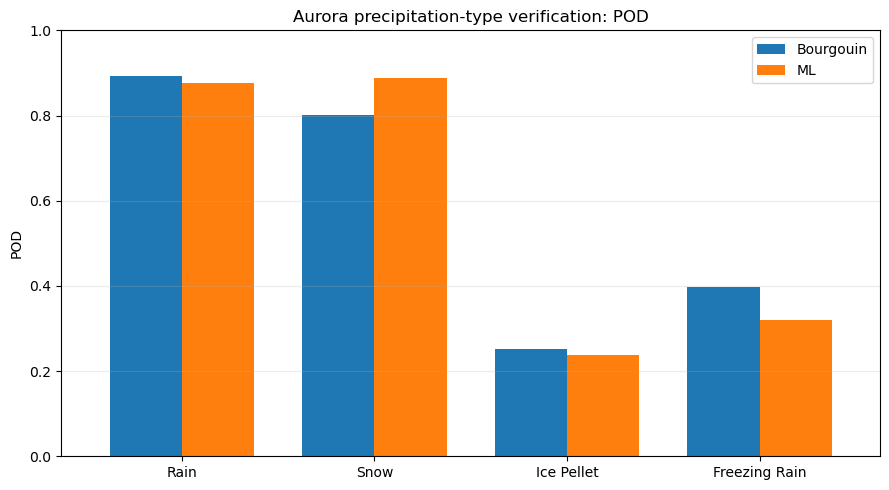

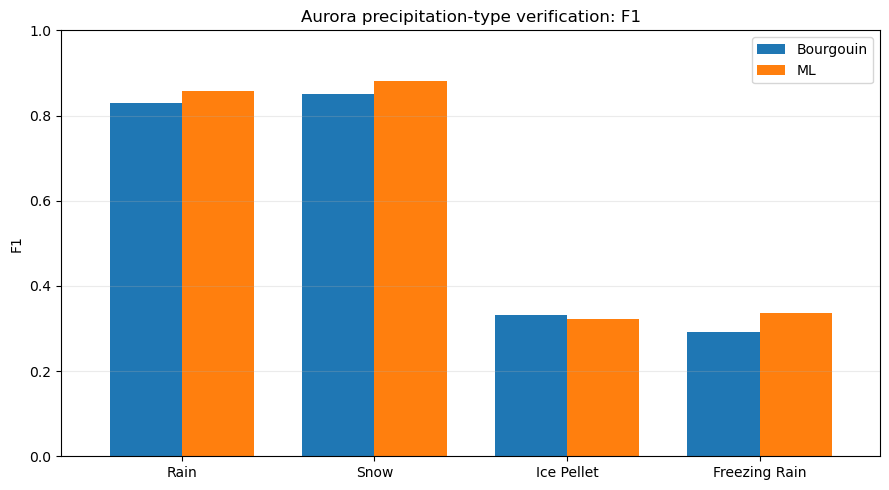

In [12]:
def plot_overall_metric(skill, metric):
    plot_df = skill.pivot(index="Class", columns="Method", values=metric).reindex(CLASS_ORDER)

    ax = plot_df.plot(kind="bar", figsize=(9, 5), width=0.75)
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.set_title(f"Aurora precipitation-type verification: {metric}")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


for metric in ["CSI", "POD", "F1"]:
    plot_overall_metric(overall_skill, metric)


## 8. Forecast-day skill curves


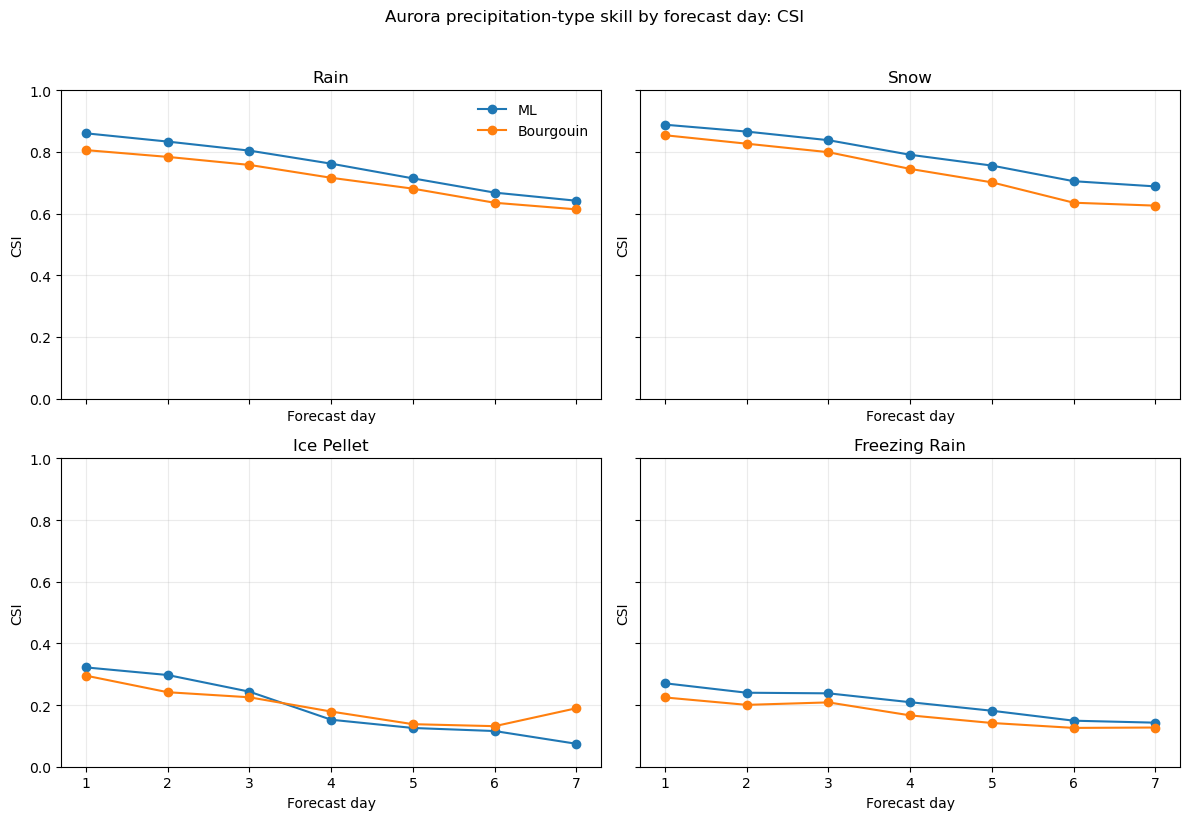

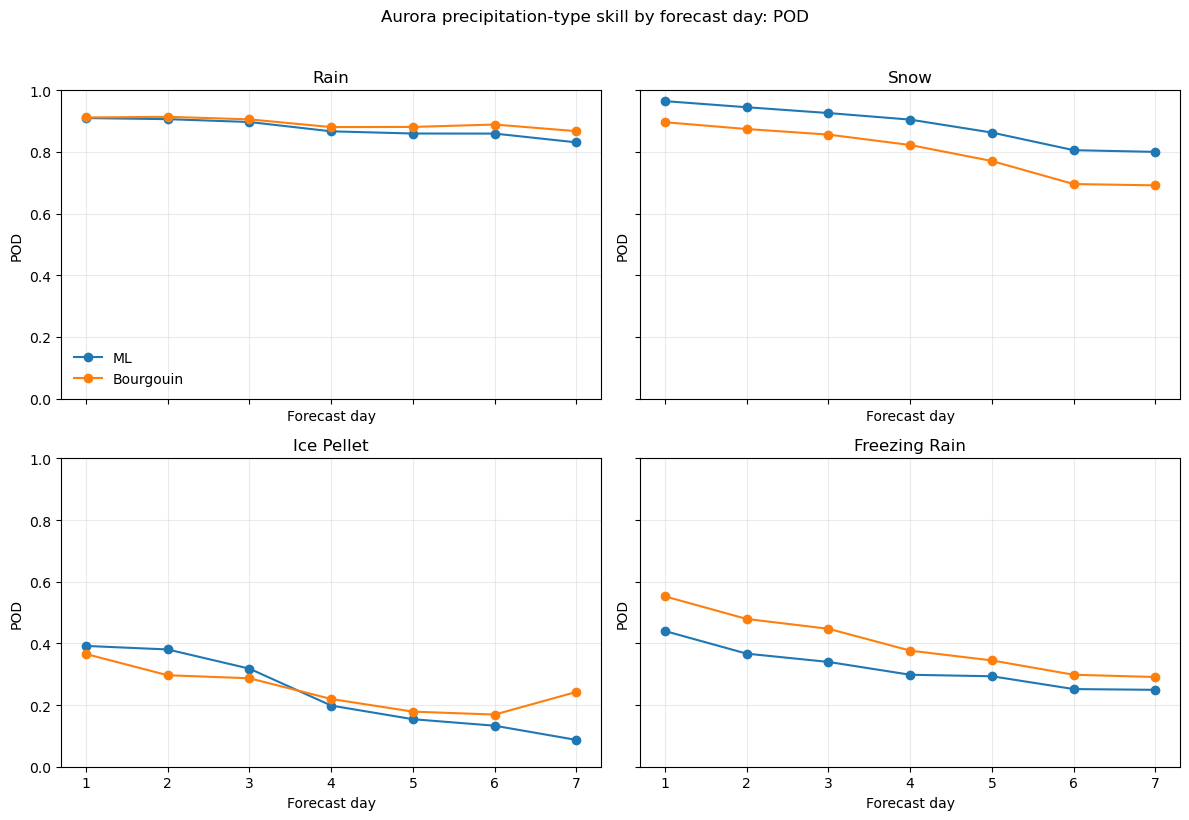

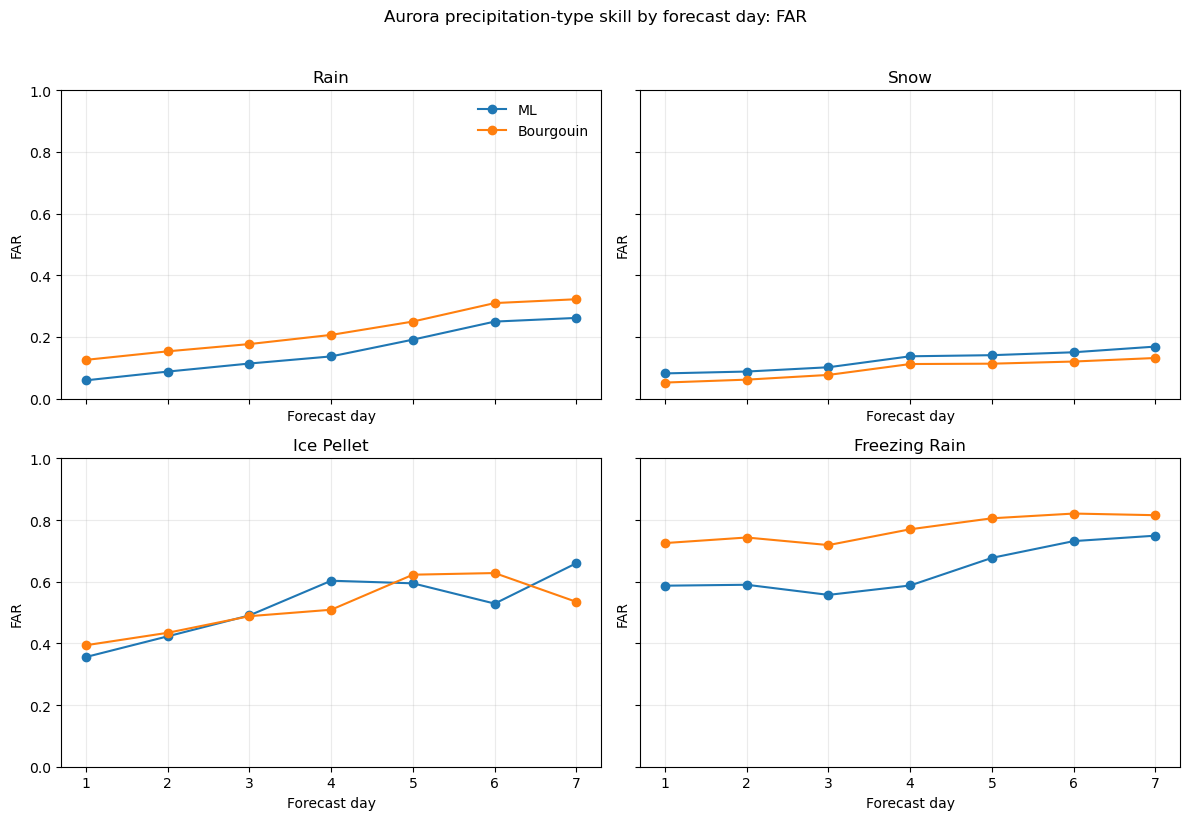

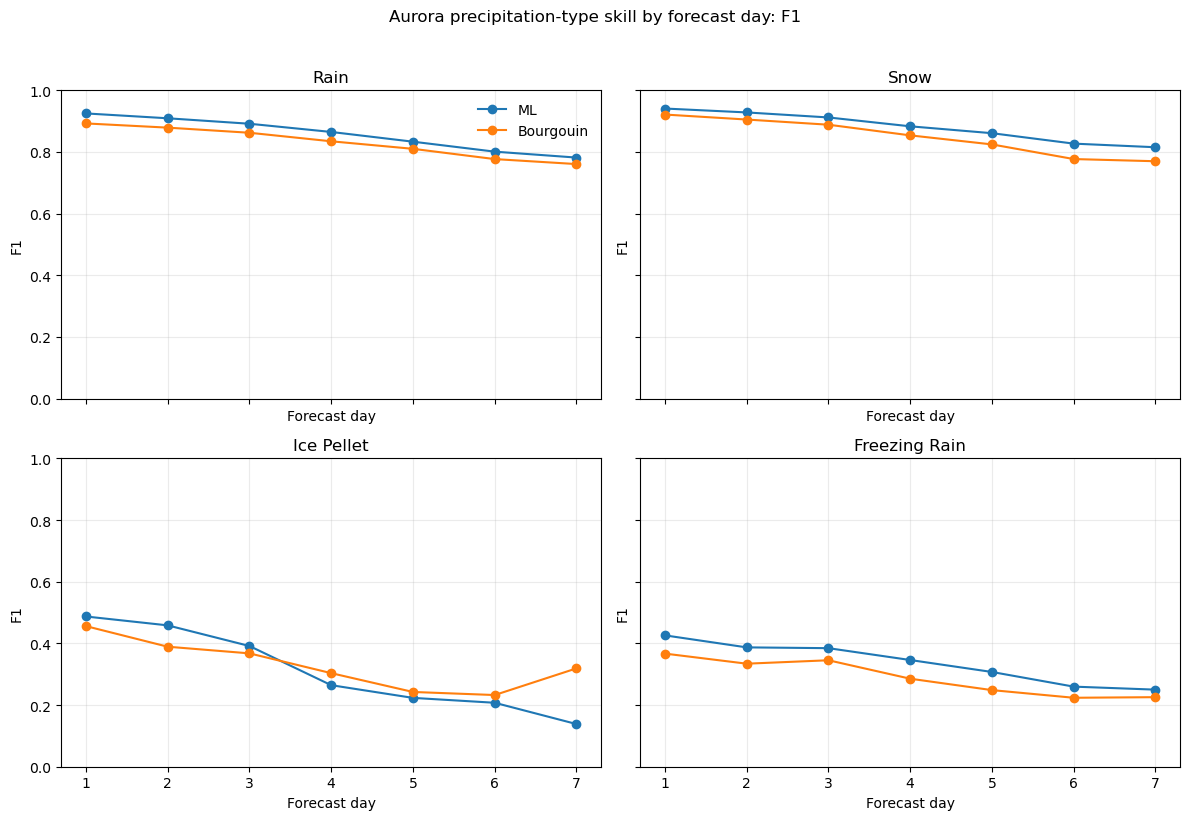

In [13]:
def plot_skill_by_day(skill, metric):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
    axes = axes.ravel()

    for ax, ptype in zip(axes, CLASS_ORDER):
        sub = skill[skill["Class"] == ptype]

        for method in ["ML", "Bourgouin"]:
            x = sub[sub["Method"] == method]
            ax.plot(x["Forecast_Day"].astype(int), x[metric], marker="o", label=method)

        ax.set_title(ptype)
        ax.set_xlabel("Forecast day")
        ax.set_ylabel(metric)
        ax.set_xticks(range(1, 8))
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.25)

    axes[0].legend(frameon=False)
    fig.suptitle(f"Aurora precipitation-type skill by forecast day: {metric}", y=1.02)
    plt.tight_layout()
    plt.show()


for metric in ["CSI", "POD", "FAR", "F1"]:
    plot_skill_by_day(daily_skill, metric)


## 9. Confusion matrices


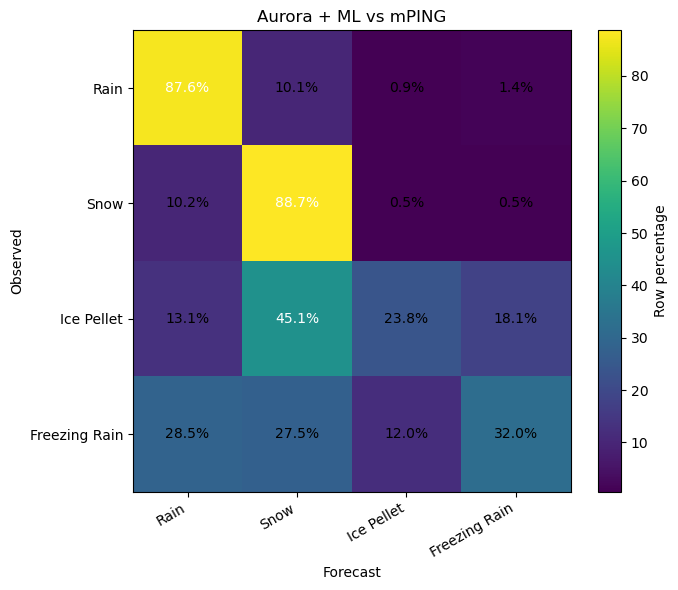

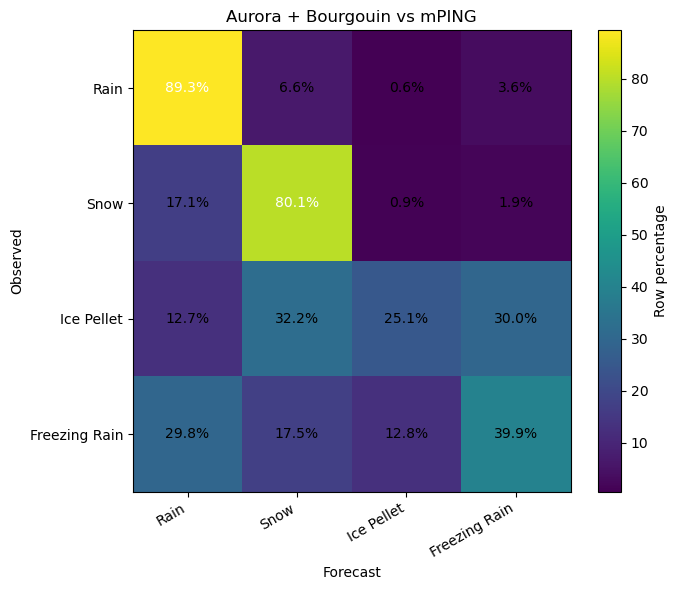

In [14]:
def confusion_matrix_df(obs, pred):
    cm = pd.crosstab(
        pd.Categorical(obs.map(CLASS_NAMES), categories=CLASS_ORDER),
        pd.Categorical(pred.map(CLASS_NAMES), categories=CLASS_ORDER),
        dropna=False,
    )
    cm.index.name = "Observed"
    cm.columns.name = "Forecast"
    return cm


def plot_confusion_matrix(obs, pred, title, normalize=True):
    cm = confusion_matrix_df(obs, pred).astype(float)

    if normalize:
        denom = cm.sum(axis=1).replace(0, np.nan)
        cm = cm.div(denom, axis=0) * 100

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm.values, aspect="auto")

    ax.set_xticks(range(len(CLASS_ORDER)), CLASS_ORDER, rotation=30, ha="right")
    ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
    ax.set_xlabel("Forecast")
    ax.set_ylabel("Observed")
    ax.set_title(title)

    threshold = np.nanmax(cm.values) / 2

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            value = cm.iloc[i, j]
            label = f"{value:.1f}%" if normalize else f"{int(value):,}"
            ax.text(
                j, i, label,
                ha="center", va="center",
                color="white" if value > threshold else "black",
            )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Row percentage" if normalize else "Count")
    plt.tight_layout()
    plt.show()


plot_confusion_matrix(
    verify["obs_code"], verify["ML_ptype"],
    "Aurora + ML vs mPING", normalize=True,
)

plot_confusion_matrix(
    verify["obs_code"], verify["BOURG_ptype"],
    "Aurora + Bourgouin vs mPING", normalize=True,
)


## 10. Forecast frequency bias


,Method,Class,Observed,Forecast,Frequency_Bias
0,ML,Rain,83282,87024,1.045
1,ML,Snow,111144,112478,1.012
2,ML,Ice Pellet,8538,4038,0.473
3,ML,Freezing Rain,5726,5150,0.899
4,Bourgouin,Rain,83282,96112,1.154
5,Bourgouin,Snow,111144,98280,0.884
6,Bourgouin,Ice Pellet,8538,4374,0.512
7,Bourgouin,Freezing Rain,5726,9924,1.733


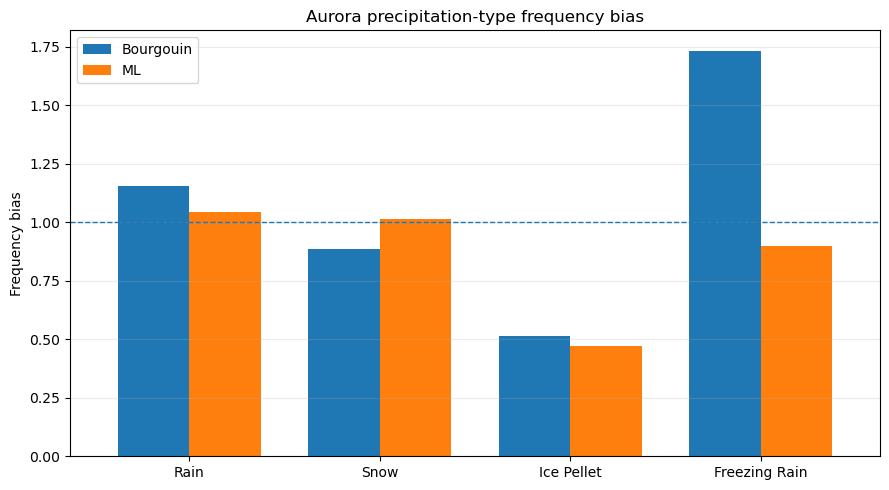

In [15]:
# Frequency bias = number forecast / number observed.
# >1 means overforecasting; <1 means underforecasting.

bias = overall_skill.copy()
bias["Frequency_Bias"] = bias["Forecast"] / bias["Observed"]

display(
    bias[["Method", "Class", "Observed", "Forecast", "Frequency_Bias"]].round(3)
)

plot_df = bias.pivot(index="Class", columns="Method", values="Frequency_Bias").reindex(CLASS_ORDER)

ax = plot_df.plot(kind="bar", figsize=(9, 5), width=0.75)
ax.axhline(1.0, linestyle="--", linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Frequency bias")
ax.set_title("Aurora precipitation-type frequency bias")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Optional: class distribution comparison


,mPING,ML,Bourgouin
Rain,83282,87024,96112
Snow,111144,112478,98280
Ice Pellet,8538,4038,4374
Freezing Rain,5726,5150,9924


,mPING,ML,Bourgouin
Rain,39.91,41.70,46.05
Snow,53.26,53.90,47.09
Ice Pellet,4.09,1.93,2.10
Freezing Rain,2.74,2.47,4.76


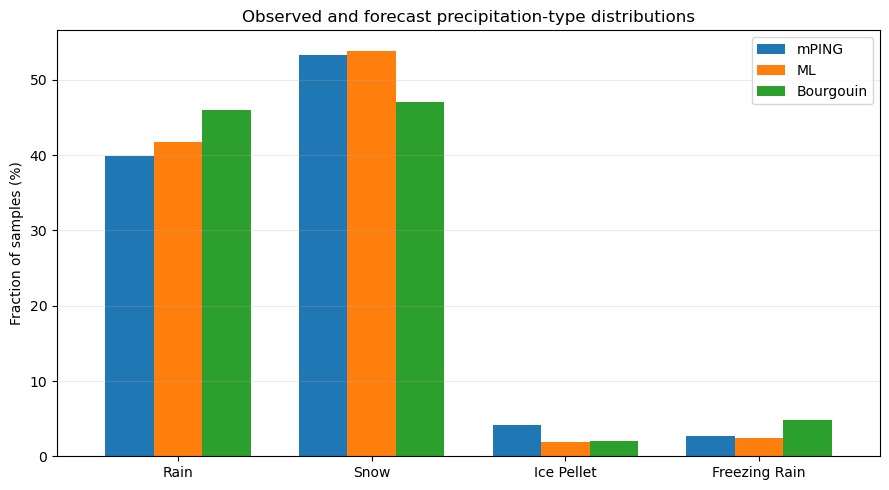

In [16]:
dist = pd.DataFrame({
    "mPING": verify["obs_code"].map(CLASS_NAMES).value_counts(),
    "ML": verify["ML_ptype"].map(CLASS_NAMES).value_counts(),
    "Bourgouin": verify["BOURG_ptype"].map(CLASS_NAMES).value_counts(),
}).reindex(CLASS_ORDER)

dist_pct = 100 * dist / dist.sum(axis=0)

display(dist)
display(dist_pct.round(2))

ax = dist_pct.plot(kind="bar", figsize=(9, 5), width=0.75)
ax.set_xlabel("")
ax.set_ylabel("Fraction of samples (%)")
ax.set_title("Observed and forecast precipitation-type distributions")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 12. Summary tables for interpretation

The tables below make it easy to identify:

- which precipitation types are most/least skillful,
- whether ML or Bourgouin has higher CSI/POD/F1 for a given class,
- whether either method systematically over- or underforecasts a class,
- and how skill changes from Forecast Day 1 to Day 7.

No significance testing is applied here; this is the first deterministic verification pass.


In [17]:
# Compact overall comparison
summary = overall_skill[
    ["Method", "Class", "Observed", "Forecast", "POD", "FAR", "CSI", "F1"]
].copy()

summary["Frequency_Bias"] = summary["Forecast"] / summary["Observed"]
display(summary.round(3))

# Compact CSI table by day
csi_by_day = daily_skill.pivot_table(
    index=["Forecast_Day", "Class"],
    columns="Method",
    values="CSI",
).reset_index()

display(csi_by_day.round(3))

# Save overall summary
SUMMARY_FILE = OUT_DIR / "aurora_mping_ptype_overall_skill.csv"
summary.to_csv(SUMMARY_FILE, index=False)
print(f"Saved: {SUMMARY_FILE}")


,Method,Class,Observed,Forecast,POD,FAR,CSI,F1,Frequency_Bias
0,ML,Rain,83282,87024,0.876,0.162,0.749,0.857,1.045
1,ML,Snow,111144,112478,0.887,0.123,0.789,0.882,1.012
2,ML,Ice Pellet,8538,4038,0.238,0.498,0.192,0.323,0.473
3,ML,Freezing Rain,5726,5150,0.320,0.644,0.203,0.337,0.899
4,Bourgouin,Rain,83282,96112,0.893,0.226,0.708,0.829,1.154
5,Bourgouin,Snow,111144,98280,0.801,0.094,0.740,0.850,0.884
6,Bourgouin,Ice Pellet,8538,4374,0.251,0.509,0.199,0.332,0.512
7,Bourgouin,Freezing Rain,5726,9924,0.399,0.770,0.171,0.292,1.733


Method,Forecast_Day,Class,Bourgouin,ML
0,1,Freezing Rain,0.225,0.271
1,1,Ice Pellet,0.295,0.322
2,1,Rain,0.806,0.861
3,1,Snow,0.854,0.889
4,2,Freezing Rain,0.201,0.240
5,2,Ice Pellet,0.242,0.297
6,2,Rain,0.784,0.834
7,2,Snow,0.827,0.866
8,3,Freezing Rain,0.209,0.238
9,3,Ice Pellet,0.225,0.243


Saved: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/verification/aurora_mping_ptype_overall_skill.csv
